# 5. Difficulty for a player of a given rating (Objective O3)

PuzzleNet predicts how hard a puzzle is for the Lichess population. The system also needs to know whether one particular
player will find a move. This compares PuzzleNet with Maia, a model of human moves, on 40,067 real critical positions.

**Source:** `eval/neural/human_difficulty.json` (`scripts/neural/human_difficulty.py`). Folds are split by player.

In [1]:
import pandas as pd
from nb_utils import ROOT, figures, load

pd.set_option('display.max_columns', None, 'display.width', 120)

human = load('eval/neural/human_difficulty.json')
print(human['positions'], 'positions,', human['players'], 'players, hit rate', human['hit_rate'])

40067 positions, 300 players, hit rate 0.6537


In [2]:
pd.DataFrame(human['models']).T.round(4)

,log_loss,brier,auc
global base rate,0.6451,0.2264,0.4983
player rating only,0.6381,0.2232,0.5713
category base rate,0.6311,0.2202,0.5858
PuzzleNet puzzle difficulty,2.0186,0.4243,0.5885
trunk + rating (human difficulty),0.6066,0.2085,0.6720
Maia at the player's level,0.5318,0.1781,0.7803
"Maia, all levels + rating",0.5171,0.1722,0.7931
trunk + rating + Maia,0.5181,0.1730,0.7905


In [3]:
pd.DataFrame(human['paired_comparisons']).T

,log_loss_difference,ci95
trunk + rating (human difficulty) vs category base rate,-0.0245,"[-0.0286, -0.0204]"
"Maia, all levels + rating vs category base rate",-0.114,"[-0.1188, -0.1089]"
"Maia, all levels + rating vs trunk + rating (human difficulty)",-0.0895,"[-0.0946, -0.0841]"
trunk + rating + Maia vs trunk + rating (human difficulty),-0.0885,"[-0.0936, -0.083]"


In [4]:
bands = pd.DataFrame(human['by_rating_band']).T
bands[['n', 'hit_rate', 'category base rate', 'trunk + rating (human difficulty)', 'Maia, all levels + rating']].round(3)

,n,hit_rate,category base rate,trunk + rating (human difficulty),"Maia, all levels + rating"
0-1200,11703.0,0.584,0.674,0.641,0.546
1200-1600,8517.0,0.645,0.635,0.628,0.522
1600-2000,9822.0,0.673,0.618,0.594,0.506
2000-3000,10025.0,0.724,0.590,0.560,0.490


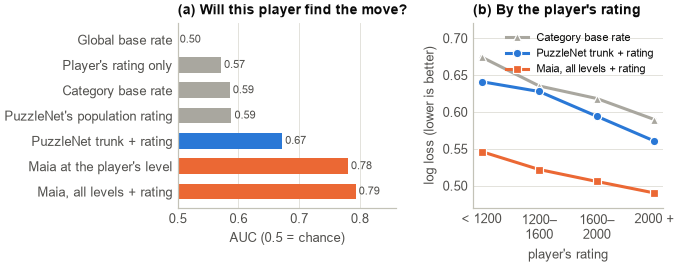

In [5]:
figures.human()

## Observations

- PuzzleNet's population rating used directly fails badly (log loss 2.02), which is the same problem seen with mined puzzles.
- A head on PuzzleNet's trunk with the player's rating beats every simple baseline (AUC 0.67).
- Maia is clearly best (AUC 0.79). Its log loss is 0.090 lower than the trunk model's (95% CI 0.084 to 0.095).
- Maia is the best model at every level of play, and adding PuzzleNet to Maia brings no further gain.
- **Conclusion:** the two are complementary. PuzzleNet judges difficulty for players in general, and Maia for one player.